# The temporal stages compared

**Temporal-stage notebook 7 in `notebooks/temporal/`.** It compares the stages the six notebooks before it show one at a time, and uses their words. `notebooks/temporal/README.md` says what the notebooks in this folder share.

## What this notebook is for

Each stage notebook ended with the stored five-seed runs of its own stage. This one sets them side by side and asks, for each pair of stages that can fairly be compared, whether the difference between them is larger than the seed-to-seed spread: on the test engines and on the held-back engines, paired by seed, with every setting each run saved laid out first.

"Fairly" carries the weight. Two runs are compared directly only when they record the same commit and, where they recorded it, the same uncommitted code outside the documentation site's folder, which training never reads. A comparison between runs of different commits is shown separately, beside a yardstick: the same configuration, run at more than one commit, and how far it moved.

## What it does not do

- **It does not train anything.** Every number comes from a stored run that names its commit.
- **It does not compare the raw-window stage.** No stored run of it exists under these settings (`06_raw_window_fd001.ipynb`).
- **It does not speak for the paper's training procedure.** Every run here holds back a fifth of the training engines and keeps the pass over the training data that did best on them, which the paper never describes. Under the procedure it does describe, the recurrent stage's advantage over the newest reading was much smaller and did not survive the seed-to-seed spread (finding F-16).
- **It does not speak for another configuration.** When the network changed on 2026-08-28, two of this project's three comparisons of settings reversed direction (working rule 3), so each result below belongs to the configuration printed with it.

## The notebook in one list

| # | Step | What goes in | What comes out |
|---|------|--------------|----------------|
| 1 | **Find the runs and read their settings** | `reports/` | every stored five-seed run of a stage under `config/fd001.yaml`, its commit and the uncommitted code it recorded, and a check that runs of one commit differ only in the stage |
| 2 | **Each stage's five seeds** | each run's `results.csv` | mean and spread on the four test measures and on the held-back engines |
| 3 | **Compare within one commit** | each pair of runs made at the same commit | the difference paired by seed, its paired test, and the seeds on its side |
| 4 | **The yardstick: one configuration at several commits** | the stages stored at more than one commit | how far the same settings moved, seed by seed |
| 5 | **Compare across commits** | the window summary against the paper's stage | the one comparison the log quotes across a commit, beside the yardstick |
| 6 | **Which published row each may be set beside** | the paper's Table 11 | a row per stage, or none |

## 1. Background

### Pairing by seed

A stored run trains five networks, seeds 42 to 46. The seed fixes three things: which 20 training engines are held back, the random numbers each network starts from, and the order the training windows arrive in. Two runs with the same seed hold back the same 20 engines whatever stage they use, because which engines are held back is drawn from the seed alone. So seed 42's network with the newest reading and seed 42's network with the paper's stage are a pair: they differ in the stage, and in what training made of it.

A **paired test** uses that. It takes the five differences, seed by seed, and asks whether their average is far from zero compared with how much they vary. With two made-up arms of five seeds, `A = [13.0, 14.1, 12.5, 13.8, 13.2]` and `B = [14.2, 14.9, 14.0, 14.7, 14.3]`:

```
differences B − A, seed by seed    [1.2, 0.8, 1.5, 0.9, 1.1]
their mean                         1.1
their standard deviation           0.274
standard error = 0.274 / √5        0.122
t = 1.1 / 0.122                    8.98
p, for t = 8.98                    0.00085    with 4 degrees of freedom
```

Each line, in words:

- The **standard deviation** says how far a single difference typically sits from the mean of the five.
- The **standard error** says how far the mean of five differences would typically sit from the mean that endlessly many seeds would give. An average of several numbers wobbles less than one number does, by the square root of how many were averaged: hence 0.274 divided by √5.
- `t` counts how many standard errors the mean lies away from zero.
- `p` is read off for that `t` from a table of chances, Student's t distribution, chosen by how many independent pieces of information the spread was measured from. That count, the **degrees of freedom**, is 5 − 1 = 4 here: the standard deviation was measured around the five differences' own mean, and once that mean is fixed only four of the five can still vary freely. With so few, the table is wide, so `t` has to be large before `p` is small.

`p` is the chance of five differences at least this far from zero if the stage made no difference and only the seed did. Here B is higher on every seed, and the test says so firmly. Set the same ten numbers side by side without the pairing — the **unpaired** test, which treats A and B as two unrelated groups of five and compares the gap between their means with the spread inside each group — and that spread, 0.64 for A, hides much of it: the unpaired test gives p = 0.010. The pairing removes the part of the seed-to-seed spread the two arms share.

**What a paired test does not answer.** Whether the difference would hold on other engines: the five seeds share one set of 100 test engines. And whether it would hold in another configuration: that needs another run.

**Many tests at once.** Testing at the usual 0.05 gives each test one chance in twenty of a false alarm, and this notebook makes several. Step 3 counts them and divides 0.05 among them, a conservative bar that a difference must clear before it is called more than the seed's doing (assumption A-37).

### Which engines should decide

A choice between two configurations should rest on the **held-back engines**, the fifth of the training engines no network trained on, not on the test engines, which are kept for the final score. The held-back figure each run records needs care of its own: it is the lowest held-back error over all passes, and it also chose which pass was kept (assumption A-18), so it flatters every run, and not necessarily by the same amount. Step 3 shows both.

**Do not confuse** the held-back error with the test error. They are computed over different engines and weighted differently — every window of 20 engines against one window each of 100 — and they are never comparable with each other (assumption A-06).

## 2. Setup

In [1]:
from __future__ import annotations

import hashlib
import json
import logging
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

# The project's top folder is the nearest one above this notebook that holds
# pyproject.toml. Adding its src/ folder to Python's search path makes the
# package importable from a clone that was never installed.
PROJECT_ROOT = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "pyproject.toml").is_file()
)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

try:
    import torch
except ImportError as missing:
    raise ImportError(
        "This notebook reads stored runs through the project's training package, which needs PyTorch, and PyTorch is "
        'not installed. Install the project with  pip install -e ".[model]"'
    ) from missing

from thesis_gnn_rul_xai.config import load_config
from thesis_gnn_rul_xai.models import ModelConfig
from scipy import stats
from thesis_gnn_rul_xai.training import TrainingConfig, find_runs
from thesis_gnn_rul_xai.utils.logging_setup import configure_logging

configure_logging(logging.ERROR)
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", None)    # a run's folder name is printed whole
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

print(f"Project root: {PROJECT_ROOT}")
print(f"PyTorch     : {torch.__version__}")

Project root: D:\Main\University\Thesis\Code\Thesis GNN RUL XAI
PyTorch     : 2.13.0+cpu


## 3. The runs

### Step 1 — Find the runs and read their settings

**What.** Every stored five-seed run, in the top of `reports/` and in the sensitivity study's folder, whose preprocessing is `config/fd001.yaml`'s and whose network is one of the stages with the rest of Table 4's sizes. The runs that saved the default training settings are laid out in full: every setting each run saved about itself — how the data was prepared, the network, the training, and how the run was organised — and which of them differ. Runs that saved nothing about their training but the learning-rate path, and no network sizes, are listed apart, because the same check cannot be made on them. Then what each run recorded of the uncommitted code it ran.

**Why.** A comparison is a fact about the configuration it was measured under, so the configuration is printed in full before any number. Runs of one commit share the committed code, but a run can also carry changes not yet committed, so those are compared too.

**Check.** Every run must have trained seeds 42 to 46; runs made at the same commit must differ, among the settings they saved, in the stage and nothing else; and where they recorded their uncommitted code, it must agree outside the documentation site's folder, `src/thesis_gnn_rul_xai/docsite/`.

In [2]:
config = load_config(PROJECT_ROOT / "config" / "fd001.yaml")
STUDY = PROJECT_ROOT / "reports" / "sensitivity_fd65a3b-dirty_20260929T101059Z" / "runs" / "FD001"
DEFAULT_TRAINING = TrainingConfig()
TRAINING_FIELDS = ("epochs", "batch_size", "learning_rate", "final_learning_rate",
                   "early_stopping_patience", "lr_schedule")
STAGES = {
    "newest reading": ModelConfig(temporal="last_cycle"),
    "window average": ModelConfig(temporal="mean_window"),
    "window summary": ModelConfig(temporal="window_summary"),
    "LSTM per sensor": ModelConfig(temporal="lstm"),
    "one LSTM for all": ModelConfig(temporal="lstm", shared_across_sensors=True),
    "GRU per sensor": ModelConfig(temporal="gru"),
    "every cycle": ModelConfig(temporal="raw_window"),
}
PAPERS_STAGE = "LSTM per sensor"
COMMAND = "python scripts/train.py --config config/fd001.yaml --temporal {} --seeds 5"


def training_settings(run) -> str:
    """'default' or 'other' from the training settings a run saved; 'not saved' if it saved only the learning-rate path."""
    recorded = run.summary.get("training")
    if recorded is None:
        return "not saved" if run.summary.get("lr_schedule") == DEFAULT_TRAINING.lr_schedule else "other"
    default = all(recorded.get(field) == getattr(DEFAULT_TRAINING, field) for field in TRAINING_FIELDS)
    return "default" if default else "other"


def stage_of(run) -> str:
    return next(label for label, wanted in STAGES.items() if run.model_config == wanted)


def label_of(run) -> str:
    return f"{stage_of(run)} @ {run.summary['commit']}"


def under_reports(run) -> str:
    return run.path.resolve().relative_to((PROJECT_ROOT / "reports").resolve()).as_posix()


found = [
    run
    for root in (None, STUDY)
    for run in find_runs(root=root, preprocessing=config, seeds=5, split="varies_with_seed", early_stopping=True)
    if run.model_config in STAGES.values()
]
runs = [run for run in found if training_settings(run) == "default"]
unsaved = {label_of(run): run for run in found if training_settings(run) == "not saved"}
missing = [label for label in STAGES if not any(stage_of(run) == label for run in runs)]
for label in missing:
    print(f"No stored five-seed run of '{label}'. Make one with\n    "
          + COMMAND.format(STAGES[label].temporal)
          + (" --shared-across-sensors" if STAGES[label].shared_across_sensors else ""))


def saved_settings(run) -> dict[str, str]:
    """Every setting the run saved about itself, except prose notes and the per-seed seed."""
    data = {f"data: {k}": v for k, v in run.preprocessing.to_dict().items() if k not in ("notes", "seed")}
    network = {f"network: {k}": v for k, v in run.model_config.to_dict().items()}
    saved = yaml.safe_load((run.path / f"seed_{run.seeds[0]}" / "training_config.yaml").read_text(encoding="utf-8"))
    training = {f"training: {k}": v for k, v in saved.items() if k not in ("notes", "seed")}
    organised = {f"run: {k}": run.summary.get(k) for k in ("seeds", "split", "validation_fraction", "early_stopping",
                                                            "reported_weights", "temporal_stage", "commit")}
    organised["run: PyTorch"] = ((run.summary.get("environment") or {}).get("packages") or {}).get("torch", "not recorded")
    return {key: str(value) for key, value in {**data, **network, **training, **organised}.items()}


names = {label_of(run): run for run in runs}
assert len(names) == len(runs), "two runs of one stage at one commit"
settings = pd.DataFrame({name: saved_settings(run) for name, run in names.items()})
same_everywhere = settings.nunique(axis=1) == 1
print(f"\n{len(names)} runs. The {int(same_everywhere.sum())} settings every one of them shares:")
display(settings[same_everywhere].iloc[:, :1].set_axis(["every run"], axis=1))
print("The settings that differ between them:")
display(settings[~same_everywhere].T)

commits = sorted({run.summary["commit"] for run in runs})
STAGE_SETTINGS = {"network: temporal", "network: shared_across_sensors", "run: temporal_stage"}
within_commit = {}
for commit in commits:
    columns = [name for name, run in names.items() if run.summary["commit"] == commit]
    differ = set(settings[columns].index[settings[columns].nunique(axis=1) > 1])
    within_commit[commit] = differ <= STAGE_SETTINGS
seeds = [42, 43, 44, 45, 46]
all_five_seeds = all(run.seeds == seeds for run in [*runs, *unsaved.values()])
only_the_stage_differs = all(within_commit.values())
assert all_five_seeds and only_the_stage_differs, within_commit
print(f"OK  every run trained seeds {seeds}; at each of the {len(commits)} commits the runs' saved settings differ "
      "only in the stage.")
for run in names.values():
    print(f"    {stage_of(run):17s} {run.summary['commit']:14s} {under_reports(run)}")
print(f"\n{len(unsaved)} more runs match every setting they saved, but saved nothing about their training except "
      "the learning-rate path, and no network sizes. Step 4 uses them; no other step does:")
for run in unsaved.values():
    print(f"    {stage_of(run):17s} {run.summary['commit']:14s} {under_reports(run)}")

No stored five-seed run of 'every cycle'. Make one with
    python scripts/train.py --config config/fd001.yaml --temporal raw_window --seeds 5

11 runs. The 31 settings every one of them shares:


,every run
data: subset,FD001
data: window_size,30
data: window_stride,1
data: rul_max,125
data: clip_test_labels,True
data: normalization,zscore
data: smoothing_alpha,0.5
data: graph,physics
data: adjacency_normalization,row
data: validation_fraction,0.2


The settings that differ between them:


,network: temporal,network: shared_across_sensors,training: device,run: temporal_stage,run: commit,run: PyTorch
LSTM per sensor @ f386291-dirty,lstm,False,auto,lstm,f386291-dirty,not recorded
newest reading @ f386291-dirty,last_cycle,False,auto,last_cycle,f386291-dirty,not recorded
window summary @ 5602773-dirty,window_summary,False,auto,window_summary,5602773-dirty,2.13.0+cpu
newest reading @ 5602773-dirty,last_cycle,False,auto,last_cycle,5602773-dirty,2.13.0+cpu
newest reading @ f4f40ad,last_cycle,False,cpu,last_cycle,f4f40ad,2.13.0+cpu
LSTM per sensor @ 19dceb5,lstm,False,cuda,lstm,19dceb5,2.5.1+cu121
newest reading @ fd65a3b-dirty,last_cycle,False,cuda,last_cycle,fd65a3b-dirty,2.5.1+cu121
window average @ fd65a3b-dirty,mean_window,False,cuda,mean_window,fd65a3b-dirty,2.5.1+cu121
LSTM per sensor @ fd65a3b-dirty,lstm,False,cuda,lstm,fd65a3b-dirty,2.5.1+cu121
GRU per sensor @ fd65a3b-dirty,gru,False,cuda,gru,fd65a3b-dirty,2.5.1+cu121


OK  every run trained seeds [42, 43, 44, 45, 46]; at each of the 5 commits the runs' saved settings differ only in the stage.
    LSTM per sensor   f386291-dirty  fd001_physics_row_cap_5seed_varsplit_lstm32_cfg72f506_f386291-dirty_20260914T134955Z
    newest reading    f386291-dirty  fd001_physics_row_cap_5seed_varsplit_cfgba82e3_f386291-dirty_20260914T150004Z
    window summary    5602773-dirty  fd001_physics_row_cap_5seed_varsplit_window_summary_cfgba82e3_5602773-dirty_20260914T233435Z
    newest reading    5602773-dirty  fd001_physics_row_cap_5seed_varsplit_cfgba82e3_5602773-dirty_20260914T233911Z
    newest reading    f4f40ad        fd001_physics_row_cap_5seed_varsplit_cfgba82e3_f4f40ad_20261002T152416Z
    LSTM per sensor   19dceb5        fd001_physics_row_cap_5seed_varsplit_lstm32_cfgba82e3_19dceb5_20261002T210700Z
    newest reading    fd65a3b-dirty  sensitivity_fd65a3b-dirty_20260929T101059Z/runs/FD001/temporal_last_cycle
    window average    fd65a3b-dirty  sensitivity_fd65a3b

**What the settings say.** Eleven runs saved their settings in full, at five commits. The 31 settings all eleven share are the configuration every number below belongs to: FD001; readings smoothed with weight 0.5 on the newest, and rescaled by the average and spread of the 80 engines each network trains on; windows of 30 cycles, one cycle apart; labels capped at 125, the test labels included; the paper's sensor graph, each row divided by its total; 20 % of the training engines held back, a different 20 for each seed, with the parameters of the pass that did best on them kept and training stopped after 20 passes without improvement; up to 200 passes in batches of 32, with the learning rate dropping from 0.001 to 0.0001 at the halfway pass; and the graph and dense layer sizes of the paper's Table 4.

They differ in the stage, and in the commit and the machine. The five at `fd65a3b-dirty` are the sensitivity study's (finding F-19), and the one at `19dceb5` is a later run of the paper's stage: all six asked for a graphics card and record PyTorch 2.5.1. The two at `5602773-dirty` asked for "auto", which takes a graphics card when PyTorch can use one, and record PyTorch 2.13.0 built for the processor alone (the `+cpu` in its name), so their "auto" meant the processor. The run at `f4f40ad` asked for the processor and records the same build. The two at `f386291-dirty` asked for "auto" and were made before runs recorded their PyTorch, so which device did their arithmetic is not recorded. Within each commit the saved settings differ in the stage alone.

The four runs listed last, at `9856794-dirty`, `ae59bc1-dirty` and `f82c76c-dirty`, saved nothing about their training but the learning-rate path, and no network sizes; the two oldest did not save their stage either, and the function that reads runs takes it to be the newest reading, which step 4 bears out. What they did not save cannot be checked, so no comparison uses them; step 4 sets them beside the others seed by seed.

In [3]:
SITE = "src/thesis_gnn_rul_xai/docsite/"


def saved_code(run) -> dict[str, str] | None:
    """Each uncommitted file a run recorded, mapped to a fingerprint of the change it saved; None if it recorded none."""
    if run.summary.get("uncommitted_code") is None:
        return None
    state = run.path / "code_state"
    patch = state / "uncommitted.patch"
    text = patch.read_text(encoding="utf-8", errors="replace") if patch.is_file() else ""
    pieces = re.split(r"(?m)^diff --git a/(\S+) b/\S+$", text)
    changes = dict(zip(pieces[1::2], pieces[2::2]))           # file -> its part of the patch
    saved = {}
    for entry in run.summary["uncommitted_code"]:             # git's short status: two letters, a space, the file
        status, path = entry[:2], entry[3:]
        if status == "??":                                    # a new file: its whole text was saved
            body = (state / "untracked" / path).read_bytes() if (state / "untracked" / path).is_file() else b"not saved"
        else:                                                 # a changed file: its part of the patch
            body = changes.get(path, "not in the patch").encode()
        saved[path] = hashlib.sha256(body).hexdigest()[:12]
    return saved


def fingerprint(saved) -> str:
    return "not recorded" if saved is None else hashlib.sha256(json.dumps(sorted(saved.items())).encode()).hexdigest()[:12]


code = {name: saved_code(run) for name, run in names.items()}
display(pd.DataFrame({
    name: {"commit": names[name].summary["commit"],
           "uncommitted files it recorded": "not recorded" if saved is None else (", ".join(saved) or "none"),
           "fingerprint of what it saved": fingerprint(saved)}
    for name, saved in code.items()}).T)

beyond_the_usual = {}                                         # run -> files where it differs from its commit's usual code
for commit in commits:
    here = [name for name, run in names.items() if run.summary["commit"] == commit]
    if len(here) < 2:
        continue
    recorded = [name for name in here if code[name] is not None]
    if not recorded:
        print(f"{commit}: none of its {len(here)} runs recorded its uncommitted code.")
        continue
    usual = pd.Series({name: fingerprint(code[name]) for name in recorded}).value_counts().index[0]
    model = next(name for name in recorded if fingerprint(code[name]) == usual)
    print(f"{commit}: {sum(fingerprint(code[name]) == usual for name in recorded)} of its {len(here)} runs recorded "
          f"the same uncommitted code, fingerprint {usual}.")
    for name in recorded:
        if fingerprint(code[name]) != usual:
            beyond_the_usual[name] = sorted(path for path in {*code[name], *code[model]}
                                            if code[name].get(path) != code[model].get(path))
            print(f"    {name} differs from them in: {', '.join(beyond_the_usual[name])}")
    for name in sorted(set(here) - set(recorded)):
        beyond_the_usual[name] = ["recorded nothing, beside runs that did"]
same_code_outside_site = all(path.startswith(SITE) for paths in beyond_the_usual.values() for path in paths)
assert same_code_outside_site, beyond_the_usual
print(f"OK  where the runs of one commit recorded their uncommitted code, it differs only in files under {SITE}.")

,commit,uncommitted files it recorded,fingerprint of what it saved
LSTM per sensor @ f386291-dirty,f386291-dirty,not recorded,not recorded
newest reading @ f386291-dirty,f386291-dirty,not recorded,not recorded
window summary @ 5602773-dirty,5602773-dirty,"scripts/train.py, src/thesis_gnn_rul_xai/models/config.py, src/thesis_gnn_rul_xai/models/temporal/__init__.py, src/thesis_gnn_rul_xai/utils/provenance.py",e226c39f1ed8
newest reading @ 5602773-dirty,5602773-dirty,"scripts/train.py, src/thesis_gnn_rul_xai/models/config.py, src/thesis_gnn_rul_xai/models/temporal/__init__.py, src/thesis_gnn_rul_xai/utils/provenance.py",e226c39f1ed8
newest reading @ f4f40ad,f4f40ad,none,4f53cda18c2b
LSTM per sensor @ 19dceb5,19dceb5,none,4f53cda18c2b
newest reading @ fd65a3b-dirty,fd65a3b-dirty,scripts/run_sensitivity.py,20c73735f55f
window average @ fd65a3b-dirty,fd65a3b-dirty,scripts/run_sensitivity.py,20c73735f55f
LSTM per sensor @ fd65a3b-dirty,fd65a3b-dirty,scripts/run_sensitivity.py,20c73735f55f
GRU per sensor @ fd65a3b-dirty,fd65a3b-dirty,scripts/run_sensitivity.py,20c73735f55f


5602773-dirty: 2 of its 2 runs recorded the same uncommitted code, fingerprint e226c39f1ed8.
f386291-dirty: none of its 2 runs recorded its uncommitted code.
fd65a3b-dirty: 4 of its 5 runs recorded the same uncommitted code, fingerprint 20c73735f55f.
    one LSTM for all @ fd65a3b-dirty differs from them in: src/thesis_gnn_rul_xai/docsite/assets/playground.js, src/thesis_gnn_rul_xai/docsite/playground.py
OK  where the runs of one commit recorded their uncommitted code, it differs only in files under src/thesis_gnn_rul_xai/docsite/.


**What the code says.** A commit names code saved into the project's history. A run made from a `-dirty` tree also ran changes not yet saved there, and the newer runs record which files those were and keep a copy of each change, in their `code_state/` folder. The table gives each run's list and a fingerprint of those copies: two runs with the same fingerprint ran the same uncommitted changes.

- At `5602773-dirty` the two runs recorded the same four changed files with one fingerprint, so they ran the same code.
- At `fd65a3b-dirty` four of the five runs recorded the same code: the commit, plus the study's own script, `scripts/run_sensitivity.py`, not yet committed. The fifth, one LSTM for all sensors, also ran changes to two files of the documentation site, `playground.js` and `playground.py` under `src/thesis_gnn_rul_xai/docsite/`. At that commit no Python file of the package outside that folder, and not `scripts/train.py`, so much as names it (checked with `git grep` on 2026-10-02), so the difference cannot have reached the training. It does mean the five did not run one identical tree.
- At `f386291-dirty` neither run recorded its uncommitted changes, so that the two ran the same code is an inference from their shared commit, not something their files show.
- The runs at `f4f40ad` and `19dceb5` ran no uncommitted changes, and each is alone at its commit.

So the runs compared in step 3 share a recorded commit and, where they recorded it, the same uncommitted code outside the documentation site's folder.

## 4. The results

### Step 2 — Each stage's five seeds

**What.** For every run, the mean and standard deviation over its five seeds of the four measures on the 100 test engines — the root mean squared error (RMSE) in cycles, the NASA score, R-squared and ASUE, all defined in notebook 02's step 11 — and of the RMSE on the held-back engines.

**Why.** One seed is not a result (working rule 3), and the spread is what a difference has to be judged against.

In [4]:
MEASURES = {"rmse": "test RMSE", "score": "test NASA score", "r2": "test R-squared", "asue": "test ASUE",
            "validation_rmse": "held-back RMSE"}


def mean_and_spread(values: pd.Series) -> str:
    return f"{values.mean():.3f} ± {values.std(ddof=1):.3f}"


per_seed = {name: run.results.set_index("seed") for name, run in names.items()}
display(pd.DataFrame({name: {label: mean_and_spread(per_seed[name][column]) for column, label in MEASURES.items()}
                      for name in names}).T)

,test RMSE,test NASA score,test R-squared,test ASUE,held-back RMSE
LSTM per sensor @ f386291-dirty,13.307 ± 0.532,330.056 ± 58.695,0.890 ± 0.009,8.938 ± 1.406,14.134 ± 0.633
newest reading @ f386291-dirty,16.496 ± 0.415,539.822 ± 44.748,0.830 ± 0.008,11.651 ± 0.995,21.168 ± 0.870
window summary @ 5602773-dirty,13.586 ± 0.675,374.656 ± 71.052,0.885 ± 0.012,8.643 ± 0.560,15.823 ± 0.461
newest reading @ 5602773-dirty,16.496 ± 0.415,539.822 ± 44.748,0.830 ± 0.008,11.651 ± 0.995,21.168 ± 0.870
newest reading @ f4f40ad,16.496 ± 0.415,539.822 ± 44.748,0.830 ± 0.008,11.651 ± 0.995,21.168 ± 0.870
LSTM per sensor @ 19dceb5,13.234 ± 0.723,316.314 ± 57.200,0.891 ± 0.012,8.146 ± 0.478,14.184 ± 0.389
newest reading @ fd65a3b-dirty,16.690 ± 0.229,572.569 ± 35.883,0.827 ± 0.005,11.296 ± 1.133,21.142 ± 0.817
window average @ fd65a3b-dirty,22.434 ± 0.516,9973.344 ± 2462.384,0.686 ± 0.014,11.386 ± 1.232,21.725 ± 1.939
LSTM per sensor @ fd65a3b-dirty,13.234 ± 0.723,316.314 ± 57.200,0.891 ± 0.012,8.146 ± 0.478,14.184 ± 0.389
GRU per sensor @ fd65a3b-dirty,12.818 ± 0.681,309.357 ± 62.588,0.897 ± 0.011,8.310 ± 0.894,13.185 ± 0.634


**Reading the table.** The seed-to-seed spread of the test RMSE runs from 0.229 to 0.723 cycles. Whether a difference between two stages is more than the seed's doing is decided by the paired test of step 3, not by setting the difference beside these spreads, because the pairing removes the part of the spread two runs of one seed share. Three rows of the newest reading — at `f386291-dirty`, `5602773-dirty` and `f4f40ad` — are one result printed three times, and the two rows of the paper's stage at `19dceb5` and `fd65a3b-dirty` another, printed twice; step 4 shows both seed by seed. The window average's NASA score, 9,973 ± 2,462, is large because that score grows exponentially with each engine's error (notebook 02's step 11 defines it), so a few large errors decide it.

### Step 3 — Compare within one commit

**What.** At every commit with more than one stage stored, each stage set against a reference, seed by seed: against the paper's stage, one LSTM per sensor, where it was stored at that commit, and otherwise against this project's default, the newest reading. The two one-number stages, the newest reading and the window average, are also set against each other, because choosing between those two was this project's own decision (assumption A-07). For each pair, on the test RMSE and on the held-back RMSE: the mean difference, the paired test, and how many of the five seeds lie on the side of the mean.

**Why.** Runs of one commit share the committed code, and step 1 showed that, where they recorded their uncommitted changes, those agree outside the documentation site's folder; so a difference between them is the stage and what training made of it. The two runs at `f386291-dirty` recorded no uncommitted changes, so for that pair this rests on the commit alone. The runs that saved no training settings are not paired here: what they did not save cannot be checked, and step 4 shows that each repeats, seed by seed, a run that is.

**Check.** Each pair must come from one commit; where both runs saved each seed's list of held-back engines, the lists must agree seed by seed; and the paired test computed here must agree with the one written by hand from the five differences.

In [5]:
pairs = []
for commit in commits:
    here = {stage_of(run): name for name, run in names.items() if run.summary["commit"] == commit}
    if len(here) < 2:
        continue
    reference = PAPERS_STAGE if PAPERS_STAGE in here else "newest reading"
    pairs += [(here[label], here[reference]) for label in here if label != reference]
    if {"newest reading", "window average"} <= set(here) and reference != "newest reading":
        pairs.append((here["window average"], here["newest reading"]))

COMPARED = {"rmse": "test RMSE", "validation_rmse": "held-back RMSE"}
tests = len(pairs) * len(COMPARED)
# ASSUMPTION A-37: a difference counts as real only below 0.05 divided by the number of
# comparisons read together, so that reading many at once does not manufacture one.
BAR = 0.05 / tests
rows = []
for name, reference in pairs:
    for column, label in COMPARED.items():
        gap = per_seed[name][column] - per_seed[reference][column]
        result = stats.ttest_rel(per_seed[name][column], per_seed[reference][column])
        rows.append({"commit": names[name].summary["commit"], "stage": stage_of(names[name]),
                     "minus": stage_of(names[reference]), "measure": label,
                     "difference": round(float(gap.mean()), 3), "paired t": round(float(result.statistic), 2),
                     "p": float(f"{result.pvalue:.2g}"),
                     "seeds on its side": int((np.sign(gap) == np.sign(gap.mean())).sum()),
                     f"below {BAR:.4f}": bool(result.pvalue < BAR)})
paired = pd.DataFrame(rows).set_index(["commit", "stage", "minus", "measure"])
print(f"{len(pairs)} pairs, {tests} paired tests; 0.05 / {tests} = {BAR:.4f}.")
display(paired)

name, reference = pairs[0]
gaps = (per_seed[name]["rmse"] - per_seed[reference]["rmse"]).to_numpy()
t_by_hand = gaps.mean() / (gaps.std(ddof=1) / np.sqrt(len(gaps)))
p_by_hand = 2 * stats.t.sf(abs(t_by_hand), df=len(gaps) - 1)
print(f"\nBy hand, {stage_of(names[name])} minus {stage_of(names[reference])} at {names[name].summary['commit']}, "
      f"test RMSE, seeds {seeds}:")
print(f"  differences {np.round(gaps, 3).tolist()}")
print(f"  mean {gaps.mean():.3f}, standard deviation {gaps.std(ddof=1):.3f}, "
      f"t = {gaps.mean():.3f} / ({gaps.std(ddof=1):.3f} / √5) = {t_by_hand:.2f}, p = {p_by_hand:.2g}")
one_commit_each = all(names[a].summary["commit"] == names[b].summary["commit"] for a, b in pairs)


def held_back(run, seed):
    """The held-back engines one seed of a run saved, or None if it saved none."""
    path = run.path / f"seed_{seed}" / "split.json"
    return json.loads(path.read_text(encoding="utf-8"))["validation"] if path.is_file() else None


saved_splits = [(a, b, seed) for a, b in pairs for seed in seeds
                if held_back(names[a], seed) is not None and held_back(names[b], seed) is not None]
same_held_back = all(held_back(names[a], seed) == held_back(names[b], seed) for a, b, seed in saved_splits)
hand_matches_scipy = bool(np.isclose(t_by_hand, paired.iloc[0]["paired t"], atol=0.01))
assert one_commit_each and same_held_back and hand_matches_scipy
no_list = sorted({name for a, b in pairs for name in (a, b) if held_back(names[name], seeds[0]) is None})
print(f"OK  every pair comes from one commit; the held-back engines agree in all {len(saved_splits)} pairs of "
      f"seeds that saved them, of {len(pairs) * len(seeds)} (saved no list: {', '.join(no_list) or 'none'}); "
      "and the hand test matches SciPy's.")

7 pairs, 14 paired tests; 0.05 / 14 = 0.0036.

difference  paired t         p  seeds on its side  \
commit        stage            minus           measure                                                             
5602773-dirty window summary   newest reading  test RMSE           -2.910    -12.37  0.000250                  5   
                                               held-back RMSE      -5.345    -22.30  0.000024                  5   
f386291-dirty newest reading   LSTM per sensor test RMSE            3.189      8.98  0.000850                  5   
                                               held-back RMSE       7.034     32.72  0.000005                  5   
fd65a3b-dirty newest reading   LSTM per sensor test RMSE            3.456      8.68  0.000970                  5   
                                               held-back RMSE       6.958     34.97  0.000004                  5   
              window average   LSTM per sensor test RMSE            9.200     20.72  0.000032                  5   
                                               held-back RMSE       7.541     10.14  0.000530                  5   
              GRU per sensor   LSTM per sensor test RMSE           -0.416     -0.83  0.460000                  4   
                                               held-back RMSE      -0.999     -5.70  0.004700                  5   
              one LSTM for all LSTM per sensor test RMSE            0.334      0.70  0.520000                  3   
                                               held-back RMSE       0.283      1.74  0.160000                  4   
              window average   newest reading  test RMSE            5.744     23.55  0.000019                  5   
                                               held-back RMSE       0.583      0.94  0.400000                  3   

                                                               below 0.0036  
commit        stage            minus           measure                       
5602773-dirty window summary   newest reading  test RMSE               True  
                                               held-back RMSE          True  
f386291-dirty newest reading   LSTM per sensor test RMSE               True  
                                               held-back RMSE          True  
fd65a3b-dirty newest reading   LSTM per sensor test RMSE               True  
                                               held-back RMSE          True  
              window average   LSTM per sensor test RMSE               True  
                                               held-back RMSE          True  
              GRU per sensor   LSTM per sensor test RMSE              False  
                                               held-back RMSE         False  
              one LSTM for all LSTM per sensor test RMSE              False  
                                               held-back RMSE         False  
              window average   newest reading  test RMSE               True  
                                               held-back RMSE         False


By hand, window summary minus newest reading at 5602773-dirty, test RMSE, seeds [42, 43, 44, 45, 46]:
  differences [-3.173, -3.157, -3.436, -2.68, -2.105]
  mean -2.910, standard deviation 0.526, t = -2.910 / (0.526 / √5) = -12.37, p = 0.00025


OK  every pair comes from one commit; the held-back engines agree in all 30 pairs of seeds that saved them, of 35 (saved no list: LSTM per sensor @ f386291-dirty, newest reading @ f386291-dirty); and the hand test matches SciPy's.


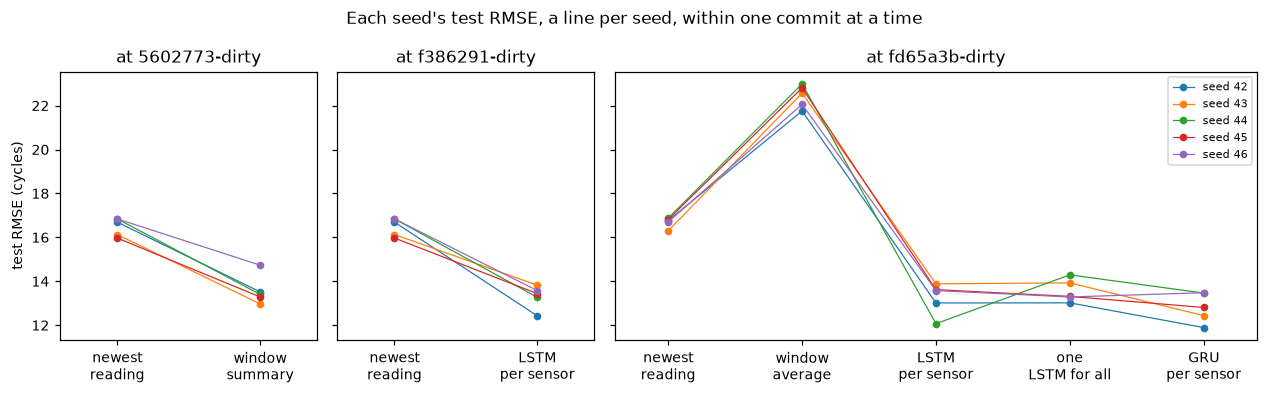

In [6]:
families = [commit for commit in commits if sum(run.summary["commit"] == commit for run in runs) > 1]
order = [label for label in STAGES if label in {stage_of(run) for run in runs}]
figure, axes = plt.subplots(1, len(families), figsize=(3.2 * len(families) + 2, 3.6), sharey=True,
                            gridspec_kw={"width_ratios": [max(2, sum(run.summary["commit"] == c for run in runs))
                                                          for c in families]})
for axis, commit in zip(np.atleast_1d(axes), families):
    here = [label for label in order if any(stage_of(run) == label and run.summary["commit"] == commit for run in runs)]
    values = np.array([[per_seed[f"{label} @ {commit}"].loc[seed, "rmse"] for label in here] for seed in seeds])
    for row, seed in zip(values, seeds):
        axis.plot(range(len(here)), row, "o-", markersize=4, linewidth=0.8, label=f"seed {seed}")
    axis.set_xticks(range(len(here)), [label.replace(" ", "\n", 1) for label in here])
    axis.set_xlim(-0.4, len(here) - 0.6)
    axis.set_title(f"at {commit}")
np.atleast_1d(axes)[0].set_ylabel("test RMSE (cycles)")
np.atleast_1d(axes)[-1].legend(fontsize=7, loc="upper right")
figure.suptitle("Each seed's test RMSE, a line per seed, within one commit at a time")
figure.tight_layout()
plt.show()

**Reading the table and the figure.** Fourteen tests, so a difference must have `p` below 0.05 / 14 = 0.0036 to be called more than the seed's doing.

- **The paper's stage against the newest reading.** At both commits that stored the two side by side, the newest reading is worse on every seed: by 3.189 cycles of test RMSE at `f386291-dirty` and 3.456 at `fd65a3b-dirty`, and by 7.034 and 6.958 on the held-back engines.
- **The window summary against the newest reading**, at `5602773-dirty`: 2.910 cycles lower on the test engines and 5.345 lower on the held-back engines, on every seed.
- **The window average** is the worst of the stages on the test engines: 9.200 cycles above the paper's stage and 5.744 above the newest reading, on every seed. On the held-back engines it cannot be told from the newest reading: +0.583, `p` = 0.40, three seeds of five on its side. That is two results on two sets of engines, not one to be explained away; the two errors are never comparable with each other (assumption A-06).
- **The GRU and one LSTM shared by all sensors** cannot be told from the paper's stage on the test engines: −0.416 cycles (`p` = 0.46) and +0.334 (`p` = 0.52). On the held-back engines the GRU is 0.999 lower on all five seeds, `p` = 0.0047, which is short of this notebook's bar.

In the figure each line is one seed. Where a difference is larger than the seed's doing, the five lines fall or rise together; between the paper's stage, the shared LSTM and the GRU they cross.

The rows at `fd65a3b-dirty` agree with the sensitivity study's own table (finding F-19); the window-summary rows and the row at `f386291-dirty` agree with the assumptions log (assumption A-28 and finding F-16).

### Step 4 — The yardstick: one configuration at several commits

**What.** The stages stored at more than one commit, seed by seed: each run's test RMSE beside the same seed's in the other runs of that stage, the runs that saved no training settings included, with what each run recorded of its machine.

**Why.** Two runs of one configuration at different commits can differ for reasons that have nothing to do with the configuration: the code between the two commits, the version of PyTorch, and whether a graphics card or the processor did the arithmetic. How far one configuration moves between two runs is the yardstick for any comparison that crosses from one run's code and machine to another's.

**Check.** Each run that saved no training settings must repeat, seed by seed and on both sets of engines, a run that saved them all. Otherwise this step measures.

In [7]:
every_run = {**names, **unsaved}


def machine(run) -> str:
    """The device a run asked for and the PyTorch build it recorded."""
    saved = run.path / f"seed_{run.seeds[0]}" / "training_config.yaml"
    device = yaml.safe_load(saved.read_text(encoding="utf-8")).get("device") if saved.is_file() else None
    build = ((run.summary.get("environment") or {}).get("packages") or {}).get("torch")
    return f"{device or 'not recorded'}, PyTorch {build or 'not recorded'}"


def both_measures(run):
    return run.results.set_index("seed").sort_index()[["rmse", "validation_rmse"]].to_numpy()


yardstick = {}
for label in order:
    stored = sorted((name for name, run in every_run.items() if stage_of(run) == label),
                    key=lambda name: every_run[name].summary.get("finished_utc", ""))
    if len(stored) < 2:
        continue
    table = pd.DataFrame({every_run[name].summary["commit"]: every_run[name].results.set_index("seed")["rmse"]
                          for name in stored})
    table["largest minus smallest"] = table.max(axis=1) - table.min(axis=1)
    yardstick[label] = table
    print(f"{label}, test RMSE, seed by seed:")
    display(table.round(6))
    for name in stored:
        print(f"    {every_run[name].summary['commit']:14s} {machine(every_run[name]):30s}"
              + ("  saved no training settings" if name in unsaved else ""))
    print()

repeats = {name: [other for other, saved in names.items() if stage_of(saved) == stage_of(run)
                  and np.array_equal(both_measures(saved), both_measures(run))]
           for name, run in unsaved.items()}
for name, twins in repeats.items():
    print(f"{name} repeats, on both sets of engines and to every stored digit: {', '.join(twins) or 'no run'}")
unsaved_runs_repeat = all(repeats.values())
assert unsaved_runs_repeat, repeats

newest reading, test RMSE, seed by seed:


,9856794-dirty,ae59bc1-dirty,f82c76c-dirty,f386291-dirty,5602773-dirty,fd65a3b-dirty,f4f40ad,largest minus smallest
seed,,,,,,,,
42,16.694915,16.694915,16.694915,16.694915,16.694915,16.761279,16.694915,0.066364
43,16.131090,16.131090,16.131090,16.131090,16.131090,16.296484,16.131090,0.165394
44,16.843242,16.843242,16.843242,16.843242,16.843242,16.875379,16.843242,0.032137
45,15.970384,15.970384,15.970384,15.970384,15.970384,16.813173,15.970384,0.842789
46,16.842666,16.842666,16.842666,16.842666,16.842666,16.704002,16.842666,0.138664


    9856794-dirty  not recorded, PyTorch not recorded  saved no training settings
    ae59bc1-dirty  not recorded, PyTorch not recorded  saved no training settings
    f82c76c-dirty  not recorded, PyTorch not recorded  saved no training settings
    f386291-dirty  auto, PyTorch not recorded    
    5602773-dirty  auto, PyTorch 2.13.0+cpu      
    fd65a3b-dirty  cuda, PyTorch 2.5.1+cu121     
    f4f40ad        cpu, PyTorch 2.13.0+cpu       

LSTM per sensor, test RMSE, seed by seed:


,f82c76c-dirty,f386291-dirty,fd65a3b-dirty,19dceb5,largest minus smallest
seed,,,,,
42,12.427376,12.427376,13.015374,13.015374,0.587998
43,13.822765,13.822765,13.884865,13.884865,0.062100
44,13.269550,13.269550,12.072373,12.072373,1.197176
45,13.437939,13.437939,13.622252,13.622252,0.184313
46,13.578974,13.578974,13.577572,13.577572,0.001402


    f82c76c-dirty  not recorded, PyTorch not recorded  saved no training settings
    f386291-dirty  auto, PyTorch not recorded    
    fd65a3b-dirty  cuda, PyTorch 2.5.1+cu121     
    19dceb5        cuda, PyTorch 2.5.1+cu121     

newest reading @ 9856794-dirty repeats, on both sets of engines and to every stored digit: newest reading @ f386291-dirty, newest reading @ 5602773-dirty, newest reading @ f4f40ad
newest reading @ ae59bc1-dirty repeats, on both sets of engines and to every stored digit: newest reading @ f386291-dirty, newest reading @ 5602773-dirty, newest reading @ f4f40ad
newest reading @ f82c76c-dirty repeats, on both sets of engines and to every stored digit: newest reading @ f386291-dirty, newest reading @ 5602773-dirty, newest reading @ f4f40ad
LSTM per sensor @ f82c76c-dirty repeats, on both sets of engines and to every stored digit: LSTM per sensor @ f386291-dirty


**Reading the tables.** For each configuration the runs fall into two groups, and within a group they give the same five test RMSEs — and, as the last lines of the cell check for the runs that saved less, the same held-back RMSEs — to every stored digit.

- **The newest reading** gives one set of five numbers at six commits, `9856794-dirty`, `ae59bc1-dirty`, `f82c76c-dirty`, `f386291-dirty`, `5602773-dirty` and `f4f40ad`, and another at `fd65a3b-dirty`. Of the six that agree, two record PyTorch built for the processor and four recorded no PyTorch version. The one that differs is the only one that records a graphics card and PyTorch 2.5.1. It differs on every seed, by between 0.032 and 0.843 cycles, and its mean by 16.690 − 16.496 = 0.194.
- **The paper's stage** gives one set at `f82c76c-dirty` and `f386291-dirty`, neither of which recorded a PyTorch version, and another at `fd65a3b-dirty` and `19dceb5`, both of which record a graphics card and PyTorch 2.5.1. Between the two sets single seeds differ by between 0.001 and 1.197 cycles, though the means differ by only 13.307 − 13.234 = 0.073.

So moving to another commit — across six for the newest reading, across two and two for the paper's stage — did not move a single stored digit. What moved one configuration, by up to 1.197 cycles on one seed, is what separates the two groups: the device and the PyTorch version, which no stored run changes one at a time, so which of the two did it is not established here. That is why step 3 pairs only runs of one commit, and within each commit the runs asked for the same device.

### Step 5 — Compare across commits

**What.** The window summary, stored only at `5602773-dirty`, against the paper's stage at `f386291-dirty`, seed by seed: the pairing the assumptions log quotes for the window summary (assumption A-28), here recomputed from the stored files.

**Why.** It is the only way to set the window summary beside a recurrent stage with the runs that exist. It crosses a commit, so it is read against step 4's yardstick.

**Check.** Among the settings they saved, the two runs must differ in the stage, the commit and the PyTorch version they recorded — the run at `f386291-dirty` recorded none — and in nothing else.

In [8]:
across = [("window summary @ 5602773-dirty", "LSTM per sensor @ f386291-dirty")]
rows = []
for name, reference in across:
    differ = set(settings.index[settings[name] != settings[reference]])
    for column, label in COMPARED.items():
        gap = per_seed[name][column] - per_seed[reference][column]
        result = stats.ttest_rel(per_seed[name][column], per_seed[reference][column])
        rows.append({"stage": f"{stage_of(names[name])} @ {names[name].summary['commit']}",
                     "minus": f"{stage_of(names[reference])} @ {names[reference].summary['commit']}",
                     "measure": label, "difference": round(float(gap.mean()), 3),
                     "paired t": round(float(result.statistic), 2), "p": float(f"{result.pvalue:.2g}"),
                     "seeds on its side": int((np.sign(gap) == np.sign(gap.mean())).sum())})
display(pd.DataFrame(rows).set_index(["stage", "minus", "measure"]))
across_differs_as_expected = differ <= STAGE_SETTINGS | {"run: commit", "run: PyTorch"}
assert across_differs_as_expected, differ
print(f"OK  the two runs differ in: {sorted(differ)}.")

difference  paired t       p  \
stage                          minus                           measure                                        
window summary @ 5602773-dirty LSTM per sensor @ f386291-dirty test RMSE            0.279      0.73  0.5100   
                                                               held-back RMSE       1.689      7.35  0.0018   

                                                                               seeds on its side  
stage                          minus                           measure                            
window summary @ 5602773-dirty LSTM per sensor @ f386291-dirty test RMSE                       3  
                                                               held-back RMSE                  5

OK  the two runs differ in: ['network: temporal', 'run: PyTorch', 'run: commit', 'run: temporal_stage'].


**Reading the table.** On the test engines the window summary and the paper's stage cannot be told apart: 0.279 cycles apart, `p` = 0.51, the window summary higher on three seeds and lower on two. On the held-back engines the paper's stage is 1.689 lower, on all five seeds, `p` = 0.0018. These are the figures the assumptions log quotes (assumption A-28), recomputed from the stored files.

The pair crosses a commit, and step 4 measured what crossing one has done so far: nothing, to the stored digits, between runs that did not differ in device and PyTorch version as far as they recorded them, and up to 1.197 cycles on one seed between runs that did. As far as the files show, this pair does not cross that line. The window summary's run records PyTorch 2.13.0 built for the processor. The paper's stage's run at `f386291-dirty` recorded no PyTorch version, but the newest reading's run at the same commit repeats the processor runs to every stored digit. The PyTorch build is still recorded on one side only, so it cannot be checked; and the window summary has been run at one commit only, so how far it would move is unmeasured. Until the two stages are run at one commit, this comparison carries that caveat.

### Step 6 — Which published row each may be set beside

**What.** For each stage, the row of the paper's Table 11 (page 12) that a result of it may stand beside, if any.

**Why.** A number from this project is comparable with a published one only if the two networks have the same parts. The paper prints the full network, 11.78 RMSE on FD001, and the network "without LSTM", 14.93, and says nothing of what the second hands the graph instead.

| Stage | May be set beside | With what said |
|---|---|---|
| newest reading | "ESTGNN w/o LSTM", 14.93 | it is this project's stand-in for what the paper leaves out (assumption A-07), not the paper's |
| window average | none | the paper names no average |
| window summary | none | no row of the paper has a stage like it (assumption A-28) |
| LSTM per sensor | "ESTGNN (Full)", 11.78 | its size is this project's choice (assumption A-26), and the best pass is restored, which the paper never describes (finding F-16) |
| one LSTM for all | none | the paper gives each sensor its own (Section 2.2) |
| GRU per sensor | none | the paper's GRU row in its Table 8 is a different method (its reference 55) |
| every cycle | none | no stored run |

Every result here is also scored against test answers capped at 125 cycles, which can only lower the RMSE and the NASA score (assumption A-02).

## Final verification

In [9]:
checks = [
    ("Every run trained seeds 42 to 46", all_five_seeds, f"{len(runs) + len(unsaved)} runs"),
    ("Runs of one commit saved settings differing only in stage", only_the_stage_differs, ", ".join(commits)),
    ("Their recorded code differs only in the site's folder", same_code_outside_site,
     f"{len(beyond_the_usual)} run(s) beyond its commit's usual code"),
    ("Every paired comparison stays within one commit", one_commit_each, f"{len(pairs)} pairs"),
    ("Paired seeds held back the same engines", same_held_back, f"{len(saved_splits)} pairs of seeds compared"),
    ("The hand paired test matches SciPy's", hand_matches_scipy, f"t = {t_by_hand:.2f}"),
    ("Each run that saved less repeats one that saved all", unsaved_runs_repeat, f"{len(unsaved)} such run(s)"),
    ("The cross-commit pair differs only in stage, commit, PyTorch", across_differs_as_expected,
     "window summary, LSTM per sensor"),
]
width = max(len(name) for name, _, _ in checks) + 2
print(f"{'CHECK':<{width}} RESULT   DETAIL")
print("-" * (width + 40))
for name, passed, detail in checks:
    print(f"{name:<{width}} {'PASS' if passed else 'FAIL':<8} {detail}")
print("-" * (width + 40))
failed = [name for name, passed, _ in checks if not passed]
if failed:
    raise AssertionError(f"{len(failed)} check(s) failed: {failed}")
print(f"All {len(checks)} checks passed.")
print(f"\nStages with no stored five-seed run under these settings: {', '.join(missing) or 'none'}.")

CHECK                                                          RESULT   DETAIL
------------------------------------------------------------------------------------------------------
Every run trained seeds 42 to 46                               PASS     15 runs
Runs of one commit saved settings differing only in stage      PASS     19dceb5, 5602773-dirty, f386291-dirty, f4f40ad, fd65a3b-dirty
Their recorded code differs only in the site's folder          PASS     1 run(s) beyond its commit's usual code
Every paired comparison stays within one commit                PASS     7 pairs
Paired seeds held back the same engines                        PASS     30 pairs of seeds compared
The hand paired test matches SciPy's                           PASS     t = -12.37
Each run that saved less repeats one that saved all            PASS     4 such run(s)
The cross-commit pair differs only in stage, commit, PyTorch   PASS     window summary, LSTM per sensor
----------------------------------------

## Summary

### What this notebook produced

- **The whole configuration** of eleven stored five-seed runs at five commits; a check that runs made at one commit differ only in the stage among the settings they saved; and what each recorded of its uncommitted code, the same at each commit where recorded, apart from two documentation-site files in one run.
- **Within one commit**, paired by seed: the paper's stage and the window summary are ahead of the newest reading on every seed, on both sets of engines; the window average is behind it on the test engines and cannot be told apart from it on the held-back engines (`p` = 0.40); the GRU and the shared LSTM cannot be told apart from the paper's stage on the test engines (`p` = 0.46 and 0.52).
- **The yardstick**: no stored digit moved between runs of one configuration at different commits, six for the newest reading and two and two for the paper's stage, when device and PyTorch version did not differ as far as recorded; between a graphics card with PyTorch 2.5.1 and the rest, single seeds moved by up to 1.197 cycles. The four runs that saved no training settings repeat runs that did, seed by seed.
- **Across a commit**: the window summary cannot be told apart from the paper's stage on the test engines (`p` = 0.51) and is 1.689 behind it on the held-back engines, with that caveat.
- **No result** for the raw-window stage, and the command that would make one.

### Decisions that were not read from the paper

| Decision | Value used | Written up as |
|---|---|---|
| Holding back a fifth of the training engines | 20 %, a different fifth for each seed | A-06 |
| When training stops, and which pass is reported | after 20 passes without improvement; the best pass | A-18 |
| Capping the test answers at 125 cycles | capped | A-02 |
| The LSTM stage's size, which the GRU stage borrows | 32 slots, one layer, one shared projection | the LSTM stage's choice (A-26), borrowed by the GRU stage (A-36) |
| What a node carries without the recurrent stage | the newest reading | A-07 |
| The window summary | newest reading, average and change | A-28 |
| The bar for many tests at once | 0.05 divided by the number of tests | A-37 |

### References

- Wen, J.-R., et al. (2026). Explainable spatiotemporal graph neutral network with dynamic SHAP enhancement for aeroengine RUL prediction. *Aerospace Science and Technology*, 168, 110875. Section 2.2, Table 4, Table 8 and Table 11.